# H3-CDN TimeVAE - Experiment 1 - Baseline

## 0. Imports

In [7]:
import os, sys, glob, time, json, hashlib, subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats, optimize
import matplotlib.pyplot as plt
import seaborn as sns

try:
    import torch
except ImportError:                      
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'torch'])
    import torch
import torch.nn as nn
import torch.nn.functional as F

warnings.filterwarnings('ignore', category=FutureWarning)

IN_KAGGLE = os.path.exists('/kaggle/working')
IN_COLAB  = 'google.colab' in sys.modules
DEVICE    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Kaggle={IN_KAGGLE}  Colab={IN_COLAB}  device={DEVICE}  torch={torch.__version__}')

Kaggle=True  Colab=False  device=cuda  torch=2.11.0+cu128


## 1. Configuration

In [8]:
# ── Paths ────────────────────────────────────────────────────────────────────
if IN_KAGGLE:
    BASE_OUT     = '/kaggle/working'
    RAW_DATA_DIR = '/kaggle/input/datasets/bishawkirti/cdn-dataset'
elif IN_COLAB:
    BASE_OUT     = '/content'
    RAW_DATA_DIR = '/content/cdn-dataset'          # upload or mount the raw files here
else:
    BASE_OUT     = '.'
    RAW_DATA_DIR = './cdn-dataset'

INPUT_CSV  = os.path.join(BASE_OUT, 'meta_cdn_aggregated.csv')   # used if it exists
EXPERIMENT = 'baseline'
OUT_DIR    = os.path.join(BASE_OUT, f'timevae_out_{EXPERIMENT}')
FIG_DIR    = os.path.join(OUT_DIR, 'figures')
OUTPUT_CSV = os.path.join(OUT_DIR, f'synthetic_cdn_{EXPERIMENT}.csv')
os.makedirs(FIG_DIR, exist_ok=True)

# ── Data / generation ────────────────────────────────────────────────────────
SEED            = 42
GRAN            = 30                      # seconds per bin
BPD             = 86400 // GRAN           # 2880 bins per day
N_DAYS          = 30
N_CLUSTERS      = 1                       # one 30-day trace = 86,400 rows
TRAIN_CLUSTERS  = ['nha', 'prn']          # fitted
TEST_CLUSTER    = 'eag'                   # never fitted; TSTR only
CHUNK_SIZE      = 500_000                 # raw reader chunk size

SCALE_MIN, SCALE_MAX     = 0.8, 2.0       # per-cluster amplitude multiplier (as before)
DIURNAL_PEAK_SHIFT_HOURS = 2.0            # per-cluster phase shift of the daily cycle
DIURNAL_FLATTEN_RANGE    = (0.85, 1.15)   # per-cluster amplitude of the daily cycle
N_FOURIER                = 8              # harmonics for the diurnal profile
DAY_SMOOTH_BINS          = BPD // 12      # 2 h ramp between day levels

# ── TimeVAE ──────────────────────────────────────────────────────────────────
WINDOW        = 480                       # 4 h windows (must be > 2 * OVERLAP)
TRAIN_STRIDE  = 12                        # 6 min stride for training windows
OVERLAP       = 60                        # 30 min cross-fade between generated windows
VAL_FRAC      = 0.15                      # last 15 % of each real cluster = validation
LATENT_DIM    = 16
HIDDEN        = [32, 64, 128]             # conv channels (3 stride-2 layers)
TREND_POLY    = 2                         # TimeVAE trend block degree
SEASONALITY   = []                        # e.g. [(4, 120)] = 4 seasons of 1 h; empty because
                                          # the daily cycle is removed before training
RECON_WT      = 3.0                       # TimeVAE default reconstruction weight
BATCH_SIZE    = 64
LR            = 1e-3
MAX_EPOCHS    = 300
PATIENCE      = 25
CLIP_STD      = 6.0                       # clip generated residuals at +/- 6 std

# ── Real-data cleaning (applied before fitting and as validation reference) ──
EDGE_FRAC     = 0.05                      # trim leading/trailing bins below 5 % of the median
SPIKE_MULT    = 10.0                      # bins above 10x the 1 h rolling median are replaced
SPIKE_WIN     = 121                       # rolling-median window (bins), about 1 h

# ── Validation tolerances (unchanged from the earlier generator) ─────────────
DIURNAL_TOL         = 0.25
ACF_TOL             = 0.08
KS_STAT_TOL         = 0.16
BURST_LO, BURST_HI  = 0.50, 2.00
TSTR_TOL            = 0.15

# ── No-repetition check (new) ────────────────────────────────────────────────
NOVELTY_WIN      = 240                    # 2 h comparison windows
COPY_CORR_HARD   = 0.95                   # no synthetic window may reach this corr
COPY_P99_MARGIN  = 0.05                   # syn p99 may exceed the real-vs-real p99 by this

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def require(*names):
    # Stop with a clear message if an earlier cell has not run in this kernel.
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(
            f'Missing {missing}. This kernel has lost earlier results (kernel restart, '
            f'or cells run out of order). Use "Run All" from the top of the notebook.')

set_seed(SEED)
assert WINDOW > 2 * OVERLAP, 'WINDOW must be larger than 2 * OVERLAP'
assert TEST_CLUSTER not in TRAIN_CLUSTERS

## 2. Load the real traces (original reader kept as fallback; fast reader used)

In [9]:
# ─────────────────────────────────────────────────────────────────────────────
#  OPTION B — RAW META CDN FILE READER (mirrors _load_meta_cdn_files exactly)
# ─────────────────────────────────────────────────────────────────────────────

# Fallback scale factors when SamplingRate is 0 / NaN.
# These are the confirmed values for Meta CDN 202303:
#   reag / rprn : SR = 0.0001 → weight = 10,000
#   rnha        : SR = 0.0004 → weight =  2,500
_CLUSTER_SCALE = {'nha': 6.37, 'prn': 4.58, 'eag': 13.4}


def _detect_cluster_from_filename(path: str) -> str:
    """
    Detect cluster name from filename.
    Handles both plain names (nha.csv) and r-prefixed names (rnha.csv).
    """
    base = os.path.basename(path).lower()
    for cname in _CLUSTER_SCALE:
        if cname in base:
            return cname
    return Path(path).stem.lstrip('r')


def load_meta_cdn_raw(
    raw_data_dir: str,
    gran: int,
    chunk_size: int = 500_000,
) -> pd.DataFrame:
    
    patterns = [
        os.path.join(raw_data_dir, '*.csv'),
        os.path.join(raw_data_dir, '*.csv.gz'),
        os.path.join(raw_data_dir, '*.zst'),
        os.path.join(raw_data_dir, '**', '*.csv'),
        os.path.join(raw_data_dir, '**', '*.csv.gz'),
    ]
    files = []
    for pat in patterns:
        files.extend(glob.glob(pat, recursive=True))
    files = sorted(set(files))

    if not files:
        raise FileNotFoundError(
            f"No CSV files found under '{raw_data_dir}'.\n"
            f"Expected: rnha.csv, rprn.csv, reag.csv\n"
            f"Download from: https://github.com/cacheMon/cache_dataset"
        )
    print(f"  Found {len(files)} raw trace file(s) in '{raw_data_dir}'")

    COL_TS, COL_RESP, COL_SR = 'timestamp', 'responseSize', 'SamplingRate'
    parts = []

    for fpath in files:
        cluster_id   = _detect_cluster_from_filename(fpath)
        scale_factor = _CLUSTER_SCALE.get(cluster_id, 1.0)
        t0           = time.time()

        # ── Detect header and separator ───────────────────────────────────
        try:
            with open(fpath, 'r') as fh:
                first_line  = fh.readline().rstrip('\n')
                second_line = fh.readline().rstrip('\n')
        except Exception:
            first_line = second_line = ''

        sep = ',' if first_line.count(',') > first_line.count(' ') else None
        raw_fields  = first_line.split(',') if sep == ',' else first_line.split()
        first_field = raw_fields[0].strip() if raw_fields else ''
        has_header  = bool(first_field) and not first_field.lstrip('-').isdigit()

        if has_header:
            header_fields = [f.strip() for f in raw_fields]
            col_map  = {name: idx for idx, name in enumerate(header_fields)}
            ts_idx   = col_map.get(COL_TS)
            resp_idx = col_map.get(COL_RESP)
            sr_idx   = col_map.get(COL_SR)
            n_cols   = len(header_fields)
        else:
            data_fields = (second_line.split(',') if sep == ','
                           else second_line.split()) if second_line else raw_fields
            n_cols = len(data_fields)
            ts_idx, resp_idx, sr_idx = 0, 4, min(9, n_cols - 1)
            header_fields = []

        missing = [name for name, idx in
                   [(COL_TS, ts_idx), (COL_RESP, resp_idx), (COL_SR, sr_idx)]
                   if idx is None or idx >= n_cols]
        if missing:
            print(f"  [SKIP] {os.path.basename(fpath)}: "
                  f"cannot locate columns {missing} — file skipped.")
            continue

        print(f"    {os.path.basename(fpath):<20s}  cluster={cluster_id}  "
              f"ts={ts_idx}  resp={resp_idx}  sr={sr_idx}  "
              f"sep={',' if sep==',' else 'space'}")

        use_idx  = sorted({ts_idx, resp_idx, sr_idx})
        read_sep = ',' if sep == ',' else ' '

        file_parts = []
        for chunk in pd.read_csv(
            fpath,
            sep=read_sep, engine='c',
            skipinitialspace=True,
            header=0 if has_header else None,
            usecols=use_idx,
            dtype='str',
            chunksize=chunk_size,
            low_memory=False,
            on_bad_lines='skip',
        ):
            if not has_header:
                chunk = chunk.rename(columns={
                    ts_idx:   COL_TS,
                    resp_idx: COL_RESP,
                    sr_idx:   COL_SR,
                })
            # Ensure canonical column names present after rename
            for col in [COL_TS, COL_RESP, COL_SR]:
                if col not in chunk.columns:
                    idx = {COL_TS: ts_idx, COL_RESP: resp_idx,
                           COL_SR: sr_idx}[col]
                    if idx in chunk.columns:
                        chunk = chunk.rename(columns={idx: col})

            chunk[COL_TS]   = pd.to_numeric(chunk[COL_TS],   errors='coerce')
            chunk[COL_RESP] = pd.to_numeric(chunk[COL_RESP], errors='coerce')
            chunk[COL_SR]   = pd.to_numeric(chunk[COL_SR],   errors='coerce')
            chunk = chunk.dropna(subset=[COL_TS])

            # Timestamp is milliseconds → seconds
            chunk['timestamp_s'] = (chunk[COL_TS] // 1000).astype('int64')
            chunk[COL_RESP]      = chunk[COL_RESP].fillna(0.0).clip(0, None)

            # Per-request weight = 1 / SamplingRate
            sr       = chunk[COL_SR].fillna(0.0)
            valid_sr = sr > 0
            weight   = pd.Series(float(scale_factor),
                                 index=chunk.index, dtype='float64')
            weight[valid_sr] = 1.0 / sr[valid_sr]

            chunk['weight']       = weight
            chunk['w_resp_bytes'] = chunk[COL_RESP] * weight
            chunk['ts_bin']       = (
                (chunk['timestamp_s'] // gran) * gran
            )
            chunk['cluster_id'] = cluster_id

            agg = (chunk.groupby(['cluster_id', 'ts_bin'])
                        .agg(req_count=('weight',       'sum'),
                             bytes_sum=('w_resp_bytes', 'sum'))
                        .reset_index())
            agg['req_rate']   = (agg['req_count'] / gran).astype('float32')
            agg['bytes_rate'] = (agg['bytes_sum'] / gran).astype('float32')
            file_parts.append(
                agg[['cluster_id', 'ts_bin', 'req_rate', 'bytes_rate']])

        elapsed = time.time() - t0
        n_bins  = sum(len(p) for p in file_parts)
        print(f"      → {n_bins:,} bins in {elapsed:.1f}s")
        parts.extend(file_parts)

    if not parts:
        raise RuntimeError(
            f"No data loaded from '{raw_data_dir}'.\n"
            f"Check that filenames contain 'nha', 'prn', or 'eag'.\n"
            f"Files found: {files}"
        )

    df = pd.concat(parts, ignore_index=True)
    # Re-aggregate across chunks — same bin may appear in multiple chunks
    df = (df.groupby(['cluster_id', 'ts_bin'])
            .agg(req_sum=('req_rate', 'sum'), byt_sum=('bytes_rate', 'sum'))
            .reset_index()
            .rename(columns={'req_sum': 'req_rate', 'byt_sum': 'bytes_rate'}))
    df[['req_rate', 'bytes_rate']] = df[['req_rate', 'bytes_rate']].astype('float32')
    df.sort_values(['cluster_id', 'ts_bin'], inplace=True)
    df.reset_index(drop=True, inplace=True)

    print(f"\n  Aggregated {len(df):,} total bins across "
          f"{df['cluster_id'].nunique()} clusters")
    for cid in sorted(df['cluster_id'].unique()):
        cdf  = df[df['cluster_id'] == cid]
        days = len(cdf) * gran / 86400
        print(f"    {cid:8s}: {len(cdf):>7,} bins  ≈{days:.1f} days  "
              f"req_rate [mean={cdf['req_rate'].mean():.2f}  "
              f"max={cdf['req_rate'].max():.2f}]")
    return df


# ─────────────────────────────────────────────────────────────────────────────
#  STEP 1  —  LOAD INPUT CSV
# ─────────────────────────────────────────────────────────────────────────────

def load_aggregated_csv(input_csv: str) -> pd.DataFrame:
   
    if not os.path.exists(input_csv):
        raise FileNotFoundError(
            f"Input CSV not found: '{input_csv}'\n"
            f"Export it from your main notebook with:\n"
            f"    df.to_csv('{input_csv}', index=False)\n"
            f"after the _load_meta_cdn_files() call."
        )

    df = pd.read_csv(input_csv, dtype={
        'cluster_id' : str,
        'ts_bin'     : 'int64',
        'req_rate'   : 'float32',
        'bytes_rate' : 'float32',
    })

    required = {'cluster_id', 'ts_bin', 'req_rate', 'bytes_rate'}
    missing  = required - set(df.columns)
    if missing:
        raise ValueError(
            f"Input CSV is missing required columns: {missing}\n"
            f"Found columns: {list(df.columns)}\n"
            f"Make sure you exported the df returned by _load_meta_cdn_files()."
        )

    df['req_rate']   = df['req_rate'].astype('float32')
    df['bytes_rate'] = df['bytes_rate'].astype('float32')
    df.sort_values(['cluster_id', 'ts_bin'], inplace=True)
    df.reset_index(drop=True, inplace=True)

    print(f"  Loaded {len(df):,} rows from '{input_csv}'")
    clusters = df['cluster_id'].unique().tolist()
    print(f"  Clusters: {clusters}")
    for cid in clusters:
        cdf = df[df['cluster_id'] == cid]
        n   = len(cdf)
        days = n * 30 / 86400   # approximate, using gran=30s default
        print(f"    {cid:8s}: {n:7,} bins  ≈{days:.1f} days  "
              f"req_rate [mean={cdf['req_rate'].mean():.2f}  "
              f"std={cdf['req_rate'].std():.2f}  "
              f"max={cdf['req_rate'].max():.2f}]")
    return df

In [10]:
# ─────────────────────────────────────────────────────────────────────────────
#  FAST RAW READER (same aggregation rules as load_meta_cdn_raw above)
# ─────────────────────────────────────────────────────────────────────────────


def _detect_layout(fpath):
    # Return (sep, has_header, ts_idx, resp_idx, sr_idx, names) like the original reader.
    with open(fpath, 'r') as fh:
        first_line = fh.readline().rstrip('\n')
        second_line = fh.readline().rstrip('\n')
    sep = ',' if first_line.count(',') > first_line.count(' ') else ' '
    raw = first_line.split(',') if sep == ',' else first_line.split()
    first_field = raw[0].strip() if raw else ''
    has_header = bool(first_field) and not first_field.lstrip('-').isdigit()
    if has_header:
        names = [f.strip() for f in raw]
        col = {n: i for i, n in enumerate(names)}
        ts_idx, resp_idx, sr_idx = (col.get('timestamp'), col.get('responseSize'),
                                    col.get('SamplingRate'))
    else:
        data = (second_line.split(',') if sep == ',' else second_line.split()) or raw
        names = [f'c{i}' for i in range(len(data))]
        ts_idx, resp_idx, sr_idx = 0, 4, min(9, len(data) - 1)
    return sep, has_header, ts_idx, resp_idx, sr_idx, names


def _aggregate_block(ts_ms, resp, sr, fallback_w, gran):
    # numpy version of the per-chunk groupby: returns (ts_bin, sum_w, sum_bytes).
    ok = np.isfinite(ts_ms)
    ts_ms, resp, sr = ts_ms[ok], resp[ok], sr[ok]
    resp = np.clip(np.nan_to_num(resp, nan=0.0), 0.0, None)
    sr = np.nan_to_num(sr, nan=0.0)
    w = np.full(len(sr), float(fallback_w))
    pos = sr > 0
    w[pos] = 1.0 / sr[pos]
    ts_bin = (np.floor_divide(ts_ms, 1000).astype(np.int64) // gran) * gran
    bins, inv = np.unique(ts_bin, return_inverse=True)
    return (bins, np.bincount(inv, weights=w, minlength=len(bins)),
            np.bincount(inv, weights=resp * w, minlength=len(bins)))


def _read_one_file_fast(fpath, cluster_id, gran, block_mb=128, report_every=50_000_000):
    import pyarrow as pa
    import pyarrow.csv as pacsv

    sep, has_header, ts_idx, resp_idx, sr_idx, names = _detect_layout(fpath)
    if sep != ',' or None in (ts_idx, resp_idx, sr_idx):
        raise ValueError('layout not supported by the fast reader')
    want = [names[ts_idx], names[resp_idx], names[sr_idx]]
    read_opts = pacsv.ReadOptions(block_size=block_mb << 20, use_threads=True,
                                  column_names=None if has_header else names)
    parse_opts = pacsv.ParseOptions(delimiter=',', invalid_row_handler=lambda row: 'skip')
    conv_opts = pacsv.ConvertOptions(include_columns=want,
                                     column_types={n: pa.float64() for n in want},
                                     strings_can_be_null=True,
                                     null_values=['', 'NA', 'NaN', 'nan', 'null', 'None'])
    fallback_w = _CLUSTER_SCALE.get(cluster_id, 1.0)
    parts, n_rows, next_report, t0 = [], 0, report_every, time.time()
    with pacsv.open_csv(fpath, read_options=read_opts, parse_options=parse_opts,
                        convert_options=conv_opts) as reader:
        for batch in reader:
            cols = [batch.column(n).to_numpy(zero_copy_only=False) for n in want]
            parts.append(_aggregate_block(cols[0], cols[1], cols[2], fallback_w, gran))
            n_rows += batch.num_rows
            if n_rows >= next_report:
                rate = n_rows / max(time.time() - t0, 1e-9)
                print(f'      ... {n_rows:,} rows read ({rate / 1e6:.1f} M rows/s)', flush=True)
                next_report += report_every
    bins = np.concatenate([p[0] for p in parts])
    u, inv = np.unique(bins, return_inverse=True)
    sw = np.bincount(inv, weights=np.concatenate([p[1] for p in parts]), minlength=len(u))
    sb = np.bincount(inv, weights=np.concatenate([p[2] for p in parts]), minlength=len(u))
    df = pd.DataFrame({'cluster_id': cluster_id, 'ts_bin': u.astype(np.int64),
                       'req_rate': (sw / gran).astype('float32'),
                       'bytes_rate': (sb / gran).astype('float32')})
    return df, n_rows


def load_meta_cdn_raw_fast(raw_data_dir, gran, clusters=None):
    # Fast drop-in for load_meta_cdn_raw. Only files of `clusters` are read.
    import tempfile
    files = []
    for pat in ['*.csv', '*.csv.gz', '**/*.csv', '**/*.csv.gz']:
        files.extend(glob.glob(os.path.join(raw_data_dir, pat), recursive=True))
    files = sorted(set(files))
    if not files:
        raise FileNotFoundError(f"No CSV files found under '{raw_data_dir}'.")
    print(f'  Found {len(files)} raw trace file(s) in {raw_data_dir!r}')

    out = []
    for fpath in files:
        cid = _detect_cluster_from_filename(fpath)
        name = os.path.basename(fpath)
        if clusters is not None and cid not in clusters:
            print(f'    {name:<20s}  cluster={cid}  [SKIP: not in {sorted(clusters)}]')
            continue
        size_gb = os.path.getsize(fpath) / 1e9
        print(f'    {name:<20s}  cluster={cid}  size={size_gb:.2f} GB', flush=True)
        t0 = time.time()
        try:
            df, n_rows = _read_one_file_fast(fpath, cid, gran)
            how = 'fast reader'
        except Exception as ex:
            print(f'      fast reader not usable ({type(ex).__name__}: {ex}); '
                  f'falling back to the original reader for this file', flush=True)
            tmp = tempfile.mkdtemp()
            os.symlink(os.path.abspath(fpath), os.path.join(tmp, name))
            df = load_meta_cdn_raw(tmp, gran, CHUNK_SIZE)
            df['cluster_id'] = cid
            n_rows, how = float('nan'), 'original reader'
        print(f'      -> {len(df):,} bins from {n_rows:,} rows in {time.time() - t0:.1f}s ({how})',
              flush=True)
        out.append(df)
    if not out:
        raise RuntimeError(f'No usable files for clusters {clusters} in {raw_data_dir!r}')

    df = (pd.concat(out, ignore_index=True)
            .groupby(['cluster_id', 'ts_bin'], as_index=False)[['req_rate', 'bytes_rate']].sum())
    df[['req_rate', 'bytes_rate']] = df[['req_rate', 'bytes_rate']].astype('float32')
    df = df.sort_values(['cluster_id', 'ts_bin']).reset_index(drop=True)
    for cid, cdf in df.groupby('cluster_id'):
        print(f'    {cid:8s}: {len(cdf):>7,} bins  ~{len(cdf) * gran / 86400:.1f} days  '
              f'mean req_rate={cdf["req_rate"].mean():,.1f}')
    return df

In [11]:
require('INPUT_CSV', 'load_aggregated_csv', 'load_meta_cdn_raw', 'load_meta_cdn_raw_fast')
if os.path.exists(INPUT_CSV):
    print(f'Loading aggregated CSV: {INPUT_CSV}')
    real_df = load_aggregated_csv(INPUT_CSV)
elif os.path.isdir(RAW_DATA_DIR):
    print(f'Reading raw traces from: {RAW_DATA_DIR}')
    real_df = load_meta_cdn_raw_fast(RAW_DATA_DIR, GRAN, set(TRAIN_CLUSTERS) | {TEST_CLUSTER})
    real_df.to_csv(INPUT_CSV, index=False)           # cache for the next run
    print(f'Aggregated table cached at {INPUT_CSV}')
else:
    raise FileNotFoundError(
        f'No input found. Put the aggregated CSV at {INPUT_CSV} '
        f'or the raw nha/prn/eag files in {RAW_DATA_DIR}.')

real_df['cluster_id'] = real_df['cluster_id'].astype(str)
missing = [c for c in TRAIN_CLUSTERS if c not in set(real_df['cluster_id'])]
if missing:
    raise ValueError(f'Training cluster(s) missing from input: {missing}')
if TEST_CLUSTER not in set(real_df['cluster_id']):
    print(f'[WARN] {TEST_CLUSTER} not found: the TSTR check will be skipped.')

Reading raw traces from: /kaggle/input/datasets/bishawkirti/cdn-dataset
  Found 4 raw trace file(s) in '/kaggle/input/datasets/bishawkirti/cdn-dataset'
    reag.csv              cluster=eag  size=7.66 GB
      ... 50,053,281 rows read (1.8 M rows/s)
      -> 23,044 bins from 50,114,842 rows in 27.3s (fast reader)
    rnha.csv              cluster=nha  size=16.84 GB
      ... 50,114,818 rows read (1.6 M rows/s)
      ... 100,044,671 rows read (1.6 M rows/s)
      -> 23,041 bins from 102,880,355 rows in 63.5s (fast reader)
    rprn.csv              cluster=prn  size=15.37 GB
      ... 50,225,725 rows read (1.4 M rows/s)
      -> 23,043 bins from 96,069,551 rows in 67.6s (fast reader)
    synthetic_cdn_timevae.csv  cluster=synthetic_cdn_timevae  [SKIP: not in ['eag', 'nha', 'prn']]
    eag     :  23,044 bins  ~8.0 days  mean req_rate=724,915.2
    nha     :  23,041 bins  ~8.0 days  mean req_rate=372,091.6
    prn     :  23,043 bins  ~8.0 days  mean req_rate=1,389,714.1
Aggregated table ca

## 3. Grid, cleaning and decomposition (log level + Fourier diurnal + day level + residual)

In [12]:
require('real_df', 'GRAN', 'BPD')

def to_regular_grid(cdf, gran):
    # Re-index one cluster to a gap-free grid; interpolate missing bins.
    cdf  = cdf.sort_values('ts_bin').drop_duplicates('ts_bin')
    full = np.arange(cdf['ts_bin'].min(), cdf['ts_bin'].max() + gran, gran, dtype=np.int64)
    s    = cdf.set_index('ts_bin')[['req_rate', 'bytes_rate']].reindex(full)
    n_gap = int(s['req_rate'].isna().sum())
    s = s.astype('float64').interpolate(limit_direction='both')
    return full, s['req_rate'].values, s['bytes_rate'].values, n_gap


def clean_cluster(ts, req, byt, edge_frac, spike_mult, win):
    # 1) Trim partial edge bins (e.g. one sampled request = 333 req/s at the trace start).
    # 2) Replace isolated extreme bins (> spike_mult x rolling median) by log-linear
    #    interpolation. One-off events cannot be learned from a single occurrence.
    med  = np.median(req)
    good = np.where(req >= edge_frac * med)[0]
    lo, hi = good[0], good[-1] + 1
    n_edge = len(req) - (hi - lo)
    ts, req, byt = ts[lo:hi], req[lo:hi].copy(), byt[lo:hi].copy()
    rmed  = pd.Series(req).rolling(win, center=True, min_periods=win // 4).median().values
    spike = req > spike_mult * rmed
    if spike.any():
        for arr in (req, byt):
            la = pd.Series(np.log(np.clip(arr, 1e-6, None)))
            la[spike] = np.nan
            arr[:] = np.exp(la.interpolate(limit_direction='both').values)
    return ts, req, byt, n_edge, np.where(spike)[0]


def fourier_design(bod, bpd, k):
    # Columns cos/sin(2*pi*h*bod/bpd) for h = 1..k (no intercept).
    ang = 2 * np.pi * np.outer(bod, np.arange(1, k + 1)) / bpd
    return np.hstack([np.cos(ang), np.sin(ang)])


def fit_diurnal(y, bod, bpd, k):
    # Least-squares Fourier fit of a zero-mean series; returns the profile for every bin-of-day.
    coef, *_ = np.linalg.lstsq(fourier_design(bod, bpd, k), y, rcond=None)
    return fourier_design(np.arange(bpd), bpd, k) @ coef


def smooth_steps(x, width):
    # Centred moving average (edge-padded) that turns day-level steps into ramps.
    if width <= 1:
        return x
    pad = width // 2
    xp  = np.pad(x, (pad, width - 1 - pad), mode='edge')
    return np.convolve(xp, np.ones(width) / width, mode='valid')


def decompose_cluster(ts, req, byt, gran, bpd, k):
    # Split one cluster into level, diurnal, day level and residual (log space).
    eps   = max(1e-6, 1e-6 * float(np.median(req[req > 0]))) if (req > 0).any() else 1e-6
    req   = np.clip(req, eps, None)
    bod   = ((ts % 86400) // gran).astype(int)
    day   = (ts // 86400).astype(int)

    lq    = np.log(req)
    mu    = lq.mean()
    d_req = fit_diurnal(lq - mu, bod, bpd, k)
    rem   = lq - mu - d_req[bod]

    # Day level from days with at least half coverage
    day_ids, inv = np.unique(day, return_inverse=True)
    cnt   = np.bincount(inv)
    lvl   = np.bincount(inv, weights=rem) / cnt
    full_days = lvl[cnt >= bpd // 2]
    lvl_t = smooth_steps(lvl[inv], DAY_SMOOTH_BINS)
    r     = rem - lvl_t

    # Bytes per request. Zero-byte bins are treated as missing and interpolated
    # in log space; the series is then winsorised at the 0.1 / 99.9 percentiles.
    lb    = pd.Series(np.log(np.where(byt > eps, byt, np.nan) / req))
    n_zero_b = int(lb.isna().sum())
    lb    = lb.interpolate(limit_direction='both').values
    lo, hi = np.percentile(lb, [0.1, 99.9])
    lb    = np.clip(lb, lo, hi)
    mu_b  = lb.mean()
    d_byt = fit_diurnal(lb - mu_b, bod, bpd, k)
    s     = lb - mu_b - d_byt[bod]

    return dict(ts=ts, req=req, byt=byt, bod=bod, mu=mu, d_req=d_req, mu_b=mu_b,
                d_byt=d_byt, day_levels=full_days, r=r, s=s,
                req_mean=float(req.mean()), n_days=len(req) / bpd, n_zero_bytes=n_zero_b)


real, cleaning_log = {}, {}
for cid in sorted(real_df['cluster_id'].unique()):
    ts, q, b, n_gap = to_regular_grid(real_df[real_df['cluster_id'] == cid], GRAN)
    raw_max = float(q.max())
    ts, q, b, n_edge, spike_idx = clean_cluster(ts, q, b, EDGE_FRAC, SPIKE_MULT, SPIKE_WIN)
    cleaning_log[cid] = dict(edge_bins_trimmed=int(n_edge), spike_bins_replaced=int(len(spike_idx)),
                             spike_times_utc=[str(pd.to_datetime(int(ts[i]), unit='s')) for i in spike_idx],
                             raw_max=raw_max, clean_max=float(q.max()))
    if n_edge or len(spike_idx):
        print(f'{cid}: trimmed {n_edge} partial edge bins; replaced {len(spike_idx)} spike bins '
              f'{cleaning_log[cid]["spike_times_utc"]}  (max {raw_max:,.0f} -> {q.max():,.0f})')
    real[cid] = decompose_cluster(ts, q, b, GRAN, BPD, N_FOURIER)
    tag = 'TRAIN' if cid in TRAIN_CLUSTERS else ('TEST' if cid == TEST_CLUSTER else 'unused')
    print(f'{cid:5s} [{tag:6s}] {len(ts):7,} bins  {real[cid]["n_days"]:.2f} days  '
          f'gaps filled={n_gap:,}  zero-byte bins={real[cid]["n_zero_bytes"]:,}  mean req={real[cid]["req_mean"]:,.1f}/s  '
          f'resid std req={real[cid]["r"].std():.3f} bytes/req={real[cid]["s"].std():.3f}')

eag: trimmed 3 partial edge bins; replaced 1 spike bins ['2023-03-18 06:26:30']  (max 6,278,000 -> 4,700,000)
eag   [TEST  ]  23,041 bins  8.00 days  gaps filled=0  zero-byte bins=0  mean req=724,796.8/s  resid std req=0.145 bytes/req=0.287
nha: trimmed 0 partial edge bins; replaced 5 spike bins ['2023-03-17 09:00:30', '2023-03-17 09:01:00', '2023-03-17 09:01:30', '2023-03-17 09:02:00', '2023-03-21 04:32:00']  (max 33,750,668 -> 3,240,833)
nha   [TRAIN ]  23,041 bins  8.00 days  gaps filled=0  zero-byte bins=0  mean req=369,245.4/s  resid std req=0.139 bytes/req=0.226
prn: trimmed 3 partial edge bins; replaced 0 spike bins []  (max 7,605,666 -> 7,605,666)
prn   [TRAIN ]  23,042 bins  8.00 days  gaps filled=2  zero-byte bins=0  mean req=1,389,785.4/s  resid std req=0.071 bytes/req=0.181


## 4. Day-level AR(1)

In [13]:
require('real')
# ── Day-level process: AR(1) across days, pooled over the training clusters ──
lv = [real[c]['day_levels'] for c in TRAIN_CLUSTERS]
DAY_SIGMA = float(np.std(np.concatenate(lv)))
pairs = [(x[:-1], x[1:]) for x in lv if len(x) >= 3]
if pairs:
    a = np.concatenate([p[0] for p in pairs]); b = np.concatenate([p[1] for p in pairs])
    DAY_PHI = float(np.clip(np.corrcoef(a, b)[0, 1], 0.0, 0.9)) if a.std() > 0 else 0.0
else:
    DAY_PHI = 0.0
print(f'Day-level AR(1): sigma={DAY_SIGMA:.4f}  phi={DAY_PHI:.3f}  (from {sum(len(x) for x in lv)} full days; rough)')

Day-level AR(1): sigma=0.0505  phi=0.437  (from 16 full days; rough)


## 5. Training windows

In [14]:
require('real', 'TRAIN_CLUSTERS')

def make_windows(x, win, stride):
    n = (len(x) - win) // stride + 1
    if n <= 0:
        return np.empty((0, win, x.shape[1]), dtype=np.float32)
    idx = np.arange(win)[None, :] + stride * np.arange(n)[:, None]
    return x[idx].astype(np.float32)

train_parts, val_parts = [], []
for c in TRAIN_CLUSTERS:
    feat  = np.stack([real[c]['r'], real[c]['s']], axis=1)
    split = int(len(feat) * (1 - VAL_FRAC))
    train_parts.append(feat[:split]); val_parts.append(feat[split:])

FEAT_MEAN = np.concatenate(train_parts).mean(axis=0)
FEAT_STD  = np.concatenate(train_parts).std(axis=0) + 1e-8
norm = lambda x: (x - FEAT_MEAN) / FEAT_STD

X_train = np.concatenate([make_windows(norm(p), WINDOW, TRAIN_STRIDE) for p in train_parts])
X_val   = np.concatenate([make_windows(norm(p), WINDOW, TRAIN_STRIDE) for p in val_parts])
C_train = C_val = None
n_indep = sum(len(p) // WINDOW for p in train_parts)
print(f'Train windows: {len(X_train):,}  (non-overlapping: {n_indep})   Val windows: {len(X_val):,}')

Train windows: 3,186  (non-overlapping: 80)   Val windows: 498


## 6. TimeVAE model (original)

In [15]:
require('X_train', 'DEVICE')

class TimeVAE(nn.Module):
    def __init__(self, seq_len, feat_dim, latent_dim, hidden, trend_poly=2, seasonality=()):
        super().__init__()
        self.T, self.C, self.Z = seq_len, feat_dim, latent_dim
        self.trend_poly, self.seasonality = trend_poly, list(seasonality)

        # Encoder
        layers, ch = [], feat_dim
        for h in hidden:
            layers += [nn.Conv1d(ch, h, 3, stride=2, padding=1), nn.ReLU()]
            ch = h
        self.encoder = nn.Sequential(*layers)
        with torch.no_grad():
            e = self.encoder(torch.zeros(1, feat_dim, seq_len))
        self.enc_ch, self.enc_len = e.shape[1], e.shape[2]
        flat = self.enc_ch * self.enc_len
        self.fc_mu, self.fc_logvar = nn.Linear(flat, latent_dim), nn.Linear(flat, latent_dim)

        # Decoder: level block
        self.level = nn.Sequential(nn.Linear(latent_dim, feat_dim), nn.ReLU(),
                                   nn.Linear(feat_dim, feat_dim))
        # Decoder: trend block
        if trend_poly > 0:
            self.trend = nn.Sequential(nn.Linear(latent_dim, feat_dim * trend_poly), nn.ReLU(),
                                       nn.Linear(feat_dim * trend_poly, feat_dim * trend_poly))
            lin = torch.arange(seq_len, dtype=torch.float32) / seq_len
            self.register_buffer('poly', torch.stack([lin ** (p + 1) for p in range(trend_poly)]))
        # Decoder: seasonal blocks
        self.season = nn.ModuleList()
        for i, (n_s, len_s) in enumerate(self.seasonality):
            self.season.append(nn.Linear(latent_dim, feat_dim * n_s))
            idx = (torch.arange(seq_len) // len_s) % n_s
            self.register_buffer(f'season_idx_{i}', idx)
        # Decoder: residual block
        self.fc_dec = nn.Linear(latent_dim, flat)
        rev, dec, ch = list(reversed(hidden)), [], hidden[-1]
        for h in rev[1:]:
            dec += [nn.ConvTranspose1d(ch, h, 3, stride=2, padding=1, output_padding=1), nn.ReLU()]
            ch = h
        dec += [nn.ConvTranspose1d(ch, feat_dim, 3, stride=2, padding=1, output_padding=1)]
        self.deconv = nn.Sequential(*dec)

    def encode(self, x):                                   # x: (B, T, C)
        h = self.encoder(x.transpose(1, 2)).flatten(1)
        return self.fc_mu(h), self.fc_logvar(h)

    def decode(self, z):                                   # returns (B, T, C)
        B = z.shape[0]
        out = self.level(z).unsqueeze(-1).expand(B, self.C, self.T)
        if self.trend_poly > 0:
            coef = self.trend(z).view(B, self.C, self.trend_poly)
            out = out + coef @ self.poly
        for i, lin in enumerate(self.season):
            n_s = self.seasonality[i][0]
            vals = lin(z).view(B, self.C, n_s)
            out = out + vals[:, :, getattr(self, f'season_idx_{i}')]
        h = F.relu(self.fc_dec(z)).view(B, self.enc_ch, self.enc_len)
        res = self.deconv(h)
        if res.shape[-1] >= self.T:
            res = res[..., :self.T]
        else:
            res = F.interpolate(res, size=self.T, mode='linear', align_corners=False)
        return (out + res).transpose(1, 2)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return self.decode(z), mu, logvar


def vae_loss(x, x_hat, mu, logvar, recon_wt):
    recon = ((x - x_hat) ** 2).sum(dim=(1, 2)).mean()
    kl    = (-0.5 * (1 + logvar - mu ** 2 - logvar.exp()).sum(dim=1)).mean()
    return recon_wt * recon + kl, recon, kl


model = TimeVAE(WINDOW, X_train.shape[2], LATENT_DIM, HIDDEN, TREND_POLY, SEASONALITY).to(DEVICE)
print(f'TimeVAE parameters: {sum(p.numel() for p in model.parameters()):,}')

TimeVAE parameters: 438,626


## 7. Training and reconstruction errors

In [16]:
require('model', 'X_train', 'X_val', 'vae_loss')
COND = C_train is not None

def fwd(xb, cb):
    return model(xb, cb) if COND else model(xb)

def run_epoch(X, Cc, train, opt=None):
    model.train(train)
    g = torch.Generator().manual_seed(SEED + run_epoch.calls); run_epoch.calls += 1
    order = torch.randperm(len(X), generator=g) if train else torch.arange(len(X))
    tot = rec = kld = 0.0
    with torch.set_grad_enabled(train):
        for i in range(0, len(X), BATCH_SIZE):
            ix = order[i:i + BATCH_SIZE].numpy()
            xb = torch.from_numpy(X[ix]).to(DEVICE)
            cb = torch.from_numpy(Cc[ix]).to(DEVICE) if COND else None
            x_hat, mu, logvar = fwd(xb, cb)
            loss, r, k = vae_loss(xb, x_hat, mu, logvar, RECON_WT)
            if train:
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step()
            n = len(xb); tot += loss.item() * n; rec += r.item() * n; kld += k.item() * n
    return tot / len(X), rec / len(X), kld / len(X)
run_epoch.calls = 0

opt   = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=8)
hist, best, best_state, wait = [], np.inf, None, 0
t0 = time.time()
for ep in range(1, MAX_EPOCHS + 1):
    tr = run_epoch(X_train, C_train, True, opt)
    va = run_epoch(X_val, C_val, False)
    sched.step(va[0]); hist.append((ep, *tr, *va))
    if va[0] < best - 1e-4:
        best, wait = va[0], 0
        best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
    if ep == 1 or ep % 10 == 0:
        print(f'ep {ep:3d}  train={tr[0]:9.2f} (rec {tr[1]:8.2f}, KL {tr[2]:6.2f})  '
              f'val={va[0]:9.2f}  lr={opt.param_groups[0]["lr"]:.1e}  {time.time()-t0:.0f}s')
    if wait >= PATIENCE:
        print(f'Early stop at epoch {ep}; best val loss {best:.2f}')
        break
model.load_state_dict(best_state)
hist = pd.DataFrame(hist, columns=['epoch', 'train_loss', 'train_rec', 'train_kl',
                                   'val_loss', 'val_rec', 'val_kl'])
hist.to_csv(os.path.join(OUT_DIR, 'timevae_training_history.csv'), index=False)
torch.save(model.state_dict(), os.path.join(OUT_DIR, 'timevae_weights.pt'))

# Posterior health and reconstruction errors (input to the noise model)
model.eval()
with torch.no_grad():
    mus, lvs, errs = [], [], []
    for i in range(0, len(X_train), 512):
        xb = torch.from_numpy(X_train[i:i + 512]).to(DEVICE)
        cb = torch.from_numpy(C_train[i:i + 512]).to(DEVICE) if COND else None
        mu, lv = model.encode(xb, cb) if COND else model.encode(xb)
        xh = model.decode(mu, cb) if COND else model.decode(mu)
        errs.append((xb - xh).cpu().numpy()); mus.append(mu.cpu().numpy()); lvs.append(lv.cpu().numpy())
mu_all, lv_all, err = np.concatenate(mus), np.concatenate(lvs), np.concatenate(errs)
kl_dim = (-0.5 * (1 + lv_all - mu_all ** 2 - np.exp(lv_all))).mean(axis=0)
active = int((kl_dim > 0.01).sum())
expl = 1 - err.reshape(-1, err.shape[2]).var(axis=0) / X_train.reshape(-1, X_train.shape[2]).var(axis=0)
print(f'Active latent dims: {active}/{LATENT_DIM}   variance explained by decoder mean: {np.round(expl, 3)}')

ep   1  train=  2459.74 (rec   808.85, KL  33.19)  val=  2342.03  lr=1.0e-03  2s
ep  10  train=  1545.56 (rec   501.39, KL  41.40)  val=  1740.15  lr=1.0e-03  5s
ep  20  train=  1494.08 (rec   484.38, KL  40.95)  val=  1745.45  lr=1.0e-03  7s
ep  30  train=  1441.58 (rec   466.42, KL  42.30)  val=  1783.90  lr=2.5e-04  10s
Early stop at epoch 37; best val loss 1721.86
Active latent dims: 16/16   variance explained by decoder mean: [0.72 0.25]


## 8. Observation-noise model

In [17]:
require('err', 'X_train')
# Observation noise: AR(1) per channel with Johnson-SU innovations (as before).

def fit_innovation_law(innov, rng):
    innov = rng.choice(innov, min(len(innov), 100_000), replace=False)
    innov = (innov - innov.mean()) / (innov.std() + 1e-12)
    try:
        a_, b_, loc_, sc_ = stats.johnsonsu.fit(innov)
        return ('johnsonsu', (a_, b_, loc_, sc_)), stats.skew(innov), stats.kurtosis(innov)
    except Exception:
        return ('normal', ()), stats.skew(innov), stats.kurtosis(innov)


def draw_innovations(n, dist, rng):
    kind, par = dist
    if kind == 'johnsonsu':
        e = stats.johnsonsu.rvs(*par, size=n, random_state=rng)
        m, v = stats.johnsonsu.stats(*par, moments='mv')
        return (e - m) / np.sqrt(v)
    return rng.standard_normal(n)


def ar_noise(n, coefs, sigma_e, dist, rng):
    # AR(p) recursion driven by unit innovations scaled to sigma_e.
    p = len(coefs); e = draw_innovations(n + 200, dist, rng) * sigma_e
    x = np.zeros(n + 200)
    for t in range(p, n + 200):
        x[t] = np.dot(coefs, x[t - p:t][::-1]) + e[t]
    return x[200:]

fit_rng = np.random.default_rng(SEED)
NOISE = []
for c in range(err.shape[2]):
    phi = float(np.clip(np.corrcoef(err[:, :-1, c].ravel(), err[:, 1:, c].ravel())[0, 1], 0.0, 0.99))
    innov = (err[:, 1:, c] - phi * err[:, :-1, c]).ravel()
    dist, sk, ku = fit_innovation_law(innov, fit_rng)
    NOISE.append(dict(coefs=np.array([phi]), sigma_e=float(innov.std()), dist=dist,
                      hour_mult=np.ones(24)))
    print(f'  channel {c}: AR(1) phi={phi:.3f}, innovation std={innov.std():.3f}, skew={sk:.2f}, kurt={ku:.2f}')

  channel 0: AR(1) phi=0.452, innovation std=0.470, skew=2.86, kurt=59.17
  channel 1: AR(1) phi=0.184, innovation std=0.849, skew=0.79, kurt=3.57


## 9. Generate one 30-day trace

In [18]:
require('model', 'real', 'NOISE', 'DAY_SIGMA', 'DAY_PHI', 'FEAT_MEAN', 'FEAT_STD', 'smooth_steps')

def stitch_windows(wins, hop, overlap, n_out):
    # Join (n, T, C) windows with a variance-preserving linear cross-fade.
    n, T, C = wins.shape
    out = np.zeros((hop * (n - 1) + T, C))
    out[:T] = wins[0]
    w = np.linspace(0, 1, overlap + 2)[1:-1][:, None]
    norm_w = np.sqrt((1 - w) ** 2 + w ** 2)
    for k in range(1, n):
        s = k * hop
        out[s:s + overlap] = ((1 - w) * out[s:s + overlap] + w * wins[k, :overlap]) / norm_w
        out[s + overlap:s + T] = wins[k, overlap:]
    return out[:n_out]


def draw_style(rng):
    # Trace-level style: identical draws in all three experiments.
    max_sh = int(DIURNAL_PEAK_SHIFT_HOURS * BPD / 24)
    return dict(u=float(rng.uniform(0, 1)), scale=float(rng.uniform(SCALE_MIN, SCALE_MAX)),
                shift=int(rng.integers(-max_sh, max_sh + 1)),
                flatten=float(rng.uniform(*DIURNAL_FLATTEN_RANGE)))

@torch.no_grad()
def sample_residuals(ts, rng):
    n_bins = len(ts)
    hop   = WINDOW - OVERLAP
    n_win = int(np.ceil((n_bins - WINDOW) / hop)) + 1
    z     = torch.from_numpy(rng.standard_normal((n_win, LATENT_DIM)).astype(np.float32)).to(DEVICE)
    wins  = np.concatenate([model.decode(z[i:i + 256]).cpu().numpy() for i in range(0, n_win, 256)])
    x     = stitch_windows(wins.astype(np.float64), hop, OVERLAP, n_bins)
    hour  = ((ts % 86400) // 3600).astype(int)
    for c in range(x.shape[1]):
        nz = NOISE[c]
        x[:, c] += ar_noise(n_bins, nz['coefs'], nz['sigma_e'], nz['dist'], rng) * nz['hour_mult'][hour]
    return np.clip(x, -CLIP_STD, CLIP_STD) * FEAT_STD + FEAT_MEAN, n_win

def generate_trace(cluster_id, start_ts, seed):
    style_rng, rng = [np.random.default_rng(s) for s in np.random.SeedSequence(seed).spawn(2)]
    st = draw_style(style_rng)
    u, scale, shift, flatten = st['u'], st['scale'], st['shift'], st['flatten']
    n_bins = N_DAYS * BPD
    t_idx  = np.arange(n_bins)
    ts     = (start_ts + t_idx * GRAN).astype(np.int64)
    bod    = t_idx % BPD                                  # start_ts is midnight UTC
    a, b   = real[TRAIN_CLUSTERS[0]], real[TRAIN_CLUSTERS[-1]]

    d_req = np.roll(u * a['d_req'] + (1 - u) * b['d_req'], shift) * flatten
    d_byt = np.roll(u * a['d_byt'] + (1 - u) * b['d_byt'], shift)
    mu_b  = u * a['mu_b'] + (1 - u) * b['mu_b']

    day_lvl = ar_noise(N_DAYS, np.array([DAY_PHI]), DAY_SIGMA * np.sqrt(1 - DAY_PHI ** 2),
                       ('normal', ()), rng)
    lvl_t   = smooth_steps(np.repeat(day_lvl, BPD), DAY_SMOOTH_BINS)

    resid, n_win = sample_residuals(ts, rng)
    log_q = d_req[bod] + lvl_t + resid[:, 0]
    log_b = mu_b + d_byt[bod] + resid[:, 1]
    extra = {}
    pass
    req   = np.exp(log_q - log_q.max())
    target_mean = (u * a['req_mean'] + (1 - u) * b['req_mean']) * scale
    req   = req * (target_mean / req.mean())
    byt   = req * np.exp(log_b)

    df = pd.DataFrame({'cluster_id': cluster_id, 'ts_bin': ts,
                       'req_rate': req.astype(np.float32), 'bytes_rate': byt.astype(np.float32)})
    meta = dict(cluster_id=cluster_id, seed=seed, n_latent_windows=n_win,
                day_levels=np.round(day_lvl, 4).tolist(), **{k: round(v, 4) if isinstance(v, float) else v
                                                              for k, v in st.items()}, **extra)
    return df, meta


ts_anchor = (min(int(real[c]['ts'].min()) for c in real) // 86400) * 86400
df, meta = generate_trace('syn001', ts_anchor, SEED)
syn_dfs, syn_meta = [df], [meta]
print(f"syn001: u={meta['u']:.2f} scale={meta['scale']:.2f} shift={meta['shift']:+d} "
      f"flatten={meta['flatten']:.2f} windows={meta['n_latent_windows']}  mean req={df['req_rate'].mean():,.1f}/s"
      + (f"  bursts={meta['n_bursts']}" if 'n_bursts' in meta else ''))

EXPECTED_ROWS = N_DAYS * BPD
assert len(syn_dfs) == 1 and len(syn_dfs[0]) == EXPECTED_ROWS
assert syn_dfs[0]['ts_bin'].diff().dropna().eq(GRAN).all()
print(f'Output shape verified: 1 trace x {EXPECTED_ROWS:,} rows; interval={GRAN}s.')

syn001: u=0.92 scale=1.89 shift=-136 flatten=0.94 windows=206  mean req=859,905.6/s
Output shape verified: 1 trace x 86,400 rows; interval=30s.


## 10. The six earlier checks (same rules and tolerances)

In [19]:
require('syn_dfs', 'real', 'fit_diurnal')

def _acf(x, max_lag=48):
    x = x - x.mean(); var = np.var(x)
    if var < 1e-12:
        return np.zeros(max_lag + 1)
    return np.array([np.mean(x[:len(x) - k] * x[k:]) / var for k in range(max_lag + 1)])


def _ar5_mae(train, test, p=5):
    n = len(train)
    X = np.stack([train[p - 1 - i:n - 1 - i] for i in range(p)], axis=1)
    c = np.linalg.lstsq(X, train[p:], rcond=None)[0]
    buf, preds = list(train[-p:]), []
    for actual in test:
        preds.append(float(np.dot(c, buf[::-1][:p])))
        buf.append(actual); buf = buf[-p:]
    return float(np.mean(np.abs(np.array(preds) - np.array(test))))


def hourly_profile(x, bod, bpd):
    bph = bpd // 24
    prof = np.bincount(bod, weights=x, minlength=bpd) / np.maximum(np.bincount(bod, minlength=bpd), 1)
    h = prof.reshape(24, bph).mean(axis=1)
    return h / (h.mean() + 1e-10)


def deseason_windows(req, ts, win):
    # Own diurnal fit + daily mean removed from log req, cut into z-normalised windows.
    lq  = np.log(np.clip(req, 1e-6, None))
    bod = ((ts % 86400) // GRAN).astype(int)
    y   = lq - lq.mean()
    y   = y - fit_diurnal(y, bod, BPD, N_FOURIER)[bod]
    day = (ts // 86400).astype(int)
    _, inv = np.unique(day, return_inverse=True)
    y   = y - (np.bincount(inv, weights=y) / np.bincount(inv))[inv]
    n   = len(y) // win
    W   = y[:n * win].reshape(n, win)
    W   = W - W.mean(axis=1, keepdims=True)
    return (W / (W.std(axis=1, keepdims=True) + 1e-8)).astype(np.float32)


def max_corr(A, B, pool, exclude_self=False, seed=0, chunk=512):
    # For each row of A: max Pearson corr with `pool` randomly chosen rows of B.
    # Rows are z-normalised. A fixed pool size keeps the max comparable across
    # tests, because the max over more candidates is larger by chance alone.
    rng, L = np.random.default_rng(seed), A.shape[1]
    pool = min(pool, len(B) - int(exclude_self))
    out = np.empty(len(A), dtype=np.float32)
    for i in range(0, len(A), chunk):
        C = A[i:i + chunk] @ B.T / L
        rows = np.arange(len(C))
        if exclude_self:
            C[rows, rows + i] = -np.inf
        cols = np.argsort(rng.random(C.shape), axis=1)[:, :pool + int(exclude_self)]
        out[i:i + chunk] = np.take_along_axis(C, cols, axis=1).max(axis=1)
    return out


def run_validation(syn_dfs):
    lines = ['=' * 66, '  H3-CDN TIMEVAE SYNTHETIC DATA - VALIDATION REPORT', '=' * 66,
                  f'  train={TRAIN_CLUSTERS}  test={TEST_CLUSTER}  seed={SEED}  '
                  f'clusters={len(syn_dfs)}  days={N_DAYS}', '']
    real_all = np.concatenate([real[c]['req'] for c in TRAIN_CLUSTERS])
    real_bod = np.concatenate([real[c]['bod'] for c in TRAIN_CLUSTERS])
    real_acf = _acf(real_all, 48)                     # pooled: information only
    real_z   = (real_all - real_all.mean()) / (real_all.std() + 1e-8)
    eag_req  = real[TEST_CLUSTER]['req'] if TEST_CLUSTER in real else np.array([])

    # Per-cluster references. Pooling nha and prn mixes two traffic levels, so
    # most pooled variance is the level gap (not traffic dynamics). Each synthetic
    # cluster is compared with each real training cluster; the closer one counts.
    R = {}
    for c in TRAIN_CLUSTERS:
        q = real[c]['req']; z = (q - q.mean()) / (q.std() + 1e-8); thr = float(np.percentile(z, 95))
        R[c] = dict(dh=hourly_profile(q, real[c]['bod'], BPD), acf=_acf(q, 48), z=z,
                    thr=thr, br=float((z > thr).mean()))
    rows = []
    for sdf in syn_dfs:
        cid = sdf['cluster_id'].iloc[0]
        sr  = sdf['req_rate'].values.astype(np.float64)
        bod = ((sdf['ts_bin'].values % 86400) // GRAN).astype(int)
        sz  = (sr - sr.mean()) / (sr.std() + 1e-8)
        dh_s, acf_s = hourly_profile(sr, bod, BPD), _acf(sr, 48)
        d = {c: float(np.max(np.abs(dh_s - R[c]['dh']))) for c in TRAIN_CLUSTERS}
        a = {c: float(np.max(np.abs(acf_s[1:] - R[c]['acf'][1:]))) for c in TRAIN_CLUSTERS}
        k = {c: float(stats.ks_2samp(R[c]['z'], sz)[0]) for c in TRAIN_CLUSTERS}
        b = {c: float((sz > R[c]['thr']).mean() / (R[c]['br'] + 1e-10)) for c in TRAIN_CLUSTERS}
        dr, ar, kr = min(d, key=d.get), min(a, key=a.get), min(k, key=k.get)
        br = min(b, key=lambda c: abs(np.log(b[c] + 1e-10)))
        rows.append(dict(cluster_id=cid, diurnal_ref=dr, diurnal_err=d[dr], acf_ref=ar, acf_diff=a[ar],
                         ks_ref=kr, ks_stat=k[kr], burst_ref=br, burst_ratio=b[br],
                         acf_diff_pooled=float(np.max(np.abs(acf_s[1:] - real_acf[1:]))),
                         **{f'acf_diff_{c}': a[c] for c in TRAIN_CLUSTERS},
                         **{f'ks_{c}': k[c] for c in TRAIN_CLUSTERS}))
    m = pd.DataFrame(rows)
    m['diurnal_ok'] = m['diurnal_err'] <= DIURNAL_TOL
    m['acf_ok']     = m['acf_diff'] <= ACF_TOL
    m['ks_ok']      = m['ks_stat'] <= KS_STAT_TOL
    m['burst_ok']   = m['burst_ratio'].between(BURST_LO, BURST_HI)

    if len(eag_req) > 10:
        trtr = _ar5_mae(real_all, eag_req); tol = trtr * (1 + TSTR_TOL)
        m['tstr_mae'] = [_ar5_mae(s['req_rate'].values.astype(np.float64), eag_req) for s in syn_dfs]
        m['tstr_ratio'] = m['tstr_mae'] / trtr
        m['tstr_ok'] = m['tstr_mae'] <= tol
        tstr_line = f'  TRTR MAE (train nha+prn, test eag) = {trtr:,.2f}; threshold = {tol:,.2f}'
    else:
        m['tstr_ok'] = np.nan; tstr_line = '  [SKIP] eag missing - TSTR not run'

    # ── Check 6: no repetition ──────────────────────────────────────────────
    full = pd.concat(syn_dfs, ignore_index=True)
    n_dup_rows = int(full.duplicated(['cluster_id', 'ts_bin']).sum())
    day_hash = [hashlib.md5(s['req_rate'].values[d * BPD:(d + 1) * BPD].tobytes()).hexdigest()
                for s in syn_dfs for d in range(len(s) // BPD)]
    n_dup_days = len(day_hash) - len(set(day_hash))
    ok_6a = (n_dup_rows == 0) and (n_dup_days == 0)

    Wr = {c: deseason_windows(real[c]['req'], real[c]['ts'], NOVELTY_WIN) for c in TRAIN_CLUSTERS}
    Wr_all = np.concatenate(list(Wr.values()))
    Ws = np.concatenate([deseason_windows(s['req_rate'].values.astype(np.float64),
                                          s['ts_bin'].values, NOVELTY_WIN) for s in syn_dfs])
    if len(TRAIN_CLUSTERS) > 1:
        c0, c1 = TRAIN_CLUSTERS[0], TRAIN_CLUSTERS[1]
        pool = min(len(Wr[c0]), len(Wr[c1]))
        base = np.concatenate([max_corr(Wr[c0], Wr[c1], pool), max_corr(Wr[c1], Wr[c0], pool)])
    else:
        pool = len(Wr_all) // 2
        base = max_corr(Wr_all, Wr_all, pool, exclude_self=True)
    syn_real = max_corr(Ws, Wr_all, pool, seed=1)
    syn_syn  = max_corr(Ws, Ws, pool, exclude_self=True, seed=2)
    b99 = float(np.percentile(base, 99))
    ok_6b = (syn_real.max() < COPY_CORR_HARD) and (np.percentile(syn_real, 99) <= b99 + COPY_P99_MARGIN)
    ok_6c = (syn_syn.max()  < COPY_CORR_HARD) and (np.percentile(syn_syn, 99)  <= b99 + COPY_P99_MARGIN)
    novelty = dict(base=base, syn_real=syn_real, syn_syn=syn_syn)

    # ── Report ──────────────────────────────────────────────────────────────
    fmt = lambda ok: 'PASS' if ok else 'FAIL'
    lines += ['Per-cluster results', '-' * 66]
    for _, r in m.iterrows():
        t = f"  TSTR {r['tstr_ratio']:.3f} {fmt(r['tstr_ok'])}" if 'tstr_ratio' in m else ''
        lines.append(f"  {r.cluster_id}: diurnal({r.diurnal_ref}) {r.diurnal_err:.3f} {fmt(r.diurnal_ok)} | "
                     f"ACF({r.acf_ref}) {r.acf_diff:.3f} {fmt(r.acf_ok)} | KS({r.ks_ref}) {r.ks_stat:.3f} "
                     f"{fmt(r.ks_ok)} | burst({r.burst_ref}) {r.burst_ratio:.2f} {fmt(r.burst_ok)} |{t}")
    lines += ['', '  Reference = the closer real training cluster for each metric.',
              f"  Pooled nha+prn ACF diff (old Check 2 target, information only): "
              f"median {m['acf_diff_pooled'].median():.3f}, max {m['acf_diff_pooled'].max():.3f}",
              tstr_line, '',
              'Check 6 - no repetition', '-' * 66,
              f'  6a duplicate rows = {n_dup_rows}, identical days = {n_dup_days}  -> {fmt(ok_6a)}',
              f'  baseline real-vs-real max corr: median {np.median(base):.3f}, p99 {b99:.3f}, '
              f'max {base.max():.3f}  (pool = {pool} windows per comparison)',
              f'  6b syn-vs-real max corr: median {np.median(syn_real):.3f}, '
              f'p99 {np.percentile(syn_real, 99):.3f}, max {syn_real.max():.3f}  -> {fmt(ok_6b)}',
              f'  6c syn-vs-syn  max corr: median {np.median(syn_syn):.3f}, '
              f'p99 {np.percentile(syn_syn, 99):.3f}, max {syn_syn.max():.3f}  -> {fmt(ok_6c)}', '']

    summary = {'diurnal': bool(m['diurnal_ok'].all()), 'acf': bool(m['acf_ok'].all()),
               'ks': bool(m['ks_ok'].all()), 'burst': bool(m['burst_ok'].all()),
               'tstr': None if m['tstr_ok'].isna().all() else bool(m['tstr_ok'].astype(bool).all()),
               'no_repetition': bool(ok_6a and ok_6b and ok_6c)}
    lines += ['=' * 66, '  SUMMARY (a check passes only if every cluster passes)', '=' * 66]
    for k, v in summary.items():
        fails = (m.loc[~m[f'{k}_ok'].astype(bool), 'cluster_id'].tolist()
                 if f'{k}_ok' in m and v is False else [])
        lines.append(f"  {k:<14}: {'SKIP' if v is None else fmt(v)}"
                     + (f'   failing: {fails}' if fails else ''))
    done = {k: v for k, v in summary.items() if v is not None}
    lines += ['', f'  Result: {sum(done.values())}/{len(done)} checks passed', '=' * 66]
    report = '\n'.join(lines)
    return report, m, summary, novelty, dict(R=R, real_acf_pooled=real_acf)

report, metrics, summary, novelty, ref = run_validation(syn_dfs)
print(report)
with open(os.path.join(OUT_DIR, 'validation_report.txt'), 'w') as f:
    f.write(report + '\n')
metrics.to_csv(os.path.join(OUT_DIR, 'validation_metrics_per_cluster.csv'), index=False)
with open(os.path.join(OUT_DIR, 'real_data_cleaning_log.json'), 'w') as f:
    json.dump(cleaning_log, f, indent=2, default=str)

  H3-CDN TIMEVAE SYNTHETIC DATA - VALIDATION REPORT
  train=['nha', 'prn']  test=eag  seed=42  clusters=1  days=30

Per-cluster results
------------------------------------------------------------------
  syn001: diurnal(prn) 0.112 PASS | ACF(nha) 0.049 PASS | KS(prn) 0.023 PASS | burst(nha) 1.29 PASS |  TSTR 0.997 PASS

  Reference = the closer real training cluster for each metric.
  Pooled nha+prn ACF diff (old Check 2 target, information only): median 0.194, max 0.194
  TRTR MAE (train nha+prn, test eag) = 43,737.87; threshold = 50,298.55

Check 6 - no repetition
------------------------------------------------------------------
  6a duplicate rows = 0, identical days = 0  -> PASS
  baseline real-vs-real max corr: median 0.411, p99 0.668, max 0.693  (pool = 96 windows per comparison)
  6b syn-vs-real max corr: median 0.417, p99 0.725, max 0.784  -> FAIL
  6c syn-vs-syn  max corr: median 0.414, p99 0.648, max 0.753  -> PASS

  SUMMARY (a check passes only if every cluster passes)
  

In [20]:
require('syn_dfs', 'real', 'fit_diurnal', 'hourly_profile', '_acf')
# ── Extended evaluation (identical in all three experiment notebooks) ────────
# Metrics follow the evaluation list in "Synthetic dataset characteristics":
# daily/weekly profiles, ACF at several lags, burst statistics, rolling
# std/max, joint req-bytes behaviour, and TSTR.
# Each metric is a distance d(A, B). For the synthetic trace we report the
# distance to the closer real training cluster. The reference scale is the
# real-vs-real distance d(nha, prn). ratio = d(syn) / d(nha, prn):
#   ratio <= 1  -> the synthetic trace is as close to real traffic as the two
#                  real clusters are to each other.
# FIDELITY = geometric mean of the ratios (each clipped to [0.05, 20]).

MULTI_LAGS = [1, 2, 10, 30, 120, 2880]          # 30 s, 1 min, 5 min, 15 min, 1 h, 1 day
ROLL = 10                                       # 5 min rolling window


def series_from(df_or_real):
    if isinstance(df_or_real, dict):
        R = df_or_real
        return R['ts'], R['req'], R['byt']
    d = df_or_real
    return d['ts_bin'].values, d['req_rate'].values.astype(float), d['bytes_rate'].values.astype(float)


def local_excess(q):
    lq = np.log(np.clip(q, 1e-9, None))
    return lq - np.log(pd.Series(q).rolling(121, center=True, min_periods=30).median().values)


def run_stats(b, e):
    edges = np.diff(np.r_[0, b.astype(int), 0])
    st, en = np.where(edges == 1)[0], np.where(edges == -1)[0]
    if len(st) == 0:
        return 0, np.nan, np.nan
    return len(st), float(np.mean(en - st)), float(np.mean([e[s:t].max() for s, t in zip(st, en)]))


def profile(x):
    ts, q, b = series_from(x)
    lq, lb = np.log(np.clip(q, 1e-9, None)), np.log(np.clip(b, 1e-9, None) / np.clip(q, 1e-9, None))
    bod = ((ts % 86400) // GRAN).astype(int)
    day = (ts // 86400).astype(int)
    dow = (day + 3) % 7
    e = local_excess(q)
    return dict(ts=ts, q=q, lq=lq, lb=lb, bod=bod, day=day, dow=dow, e=e,
                n_days=len(q) / BPD, hp=hourly_profile(q, bod, BPD), acf48=_acf(q, 48),
                mlag=np.array([np.corrcoef(lq[:-k], lq[k:])[0, 1] for k in MULTI_LAGS]),
                z=(q - q.mean()) / (q.std() + 1e-12),
                rstd=pd.Series(e).rolling(ROLL).std().dropna().values,
                rmax=pd.Series(e).rolling(ROLL).max().dropna().values,
                zb=(lb - lb.mean()) / (lb.std() + 1e-12))


def weekend_diff(P):
    dm = pd.DataFrame(dict(day=P['day'], dow=P['dow'], q=P['q'])).groupby('day').agg(
        n=('q', 'size'), med=('q', 'median'), dow=('dow', 'first'))
    dm = dm[dm['n'] >= 0.9 * BPD]
    we = dm['dow'] >= 5
    if we.sum() == 0 or (~we).sum() == 0:
        return np.nan
    return float(np.log(dm['med'][we]).mean() - np.log(dm['med'][~we]).mean())


def xcorr(P, lags=range(-5, 6)):
    a, b = np.diff(P['lq']), np.diff(P['lb'])
    a, b = (a - a.mean()) / a.std(), (b - b.mean()) / b.std()
    return np.array([np.mean(a[max(0, -k):len(a) - max(0, k)] * b[max(0, k):len(b) - max(0, -k)])
                     for k in lags])


def distances(S, R):
    # Distance of profile S to reference profile R (burst threshold from R).
    thr = np.nanpercentile(R['e'], 99)
    bs, br = S['e'] > thr, R['e'] > thr
    ns, ds, ps = run_stats(bs, S['e']); nr, dr, pr = run_stats(br, R['e'])
    burst_d = np.nanmean([abs(np.log((ns / S['n_days'] + 1e-6) / (nr / R['n_days'] + 1e-6))),
                          abs(np.log(ds / dr)) if ns and nr else np.nan,
                          abs(np.log(ps / pr)) if ns and nr else np.nan])
    bpr_shift = lambda P, b: float(np.median(P['lb'][b]) - np.median(P['lb'][~b])) if b.any() else 0.0
    return {
        'diurnal_profile':   float(np.max(np.abs(S['hp'] - R['hp']))),
        'acf_lags_1_48':     float(np.max(np.abs(S['acf48'][1:] - R['acf48'][1:]))),
        'acf_multi_lag':     float(np.max(np.abs(S['mlag'] - R['mlag']))),
        'marginal_ks':       float(stats.ks_2samp(S['z'], R['z'])[0]),
        'burst_stats':       float(burst_d),
        'rolling_std_max':   float(np.mean([stats.ks_2samp(S['rstd'], R['rstd'])[0],
                                            stats.ks_2samp(S['rmax'], R['rmax'])[0]])),
        'weekend_effect':    float(abs(weekend_diff(S) - weekend_diff(R))),
        'joint_corr':        float(abs(stats.spearmanr(S['lq'], S['lb'])[0] - stats.spearmanr(R['lq'], R['lb'])[0])),
        'joint_xcorr':       float(np.max(np.abs(xcorr(S) - xcorr(R)))),
        'bpr_in_bursts':     float(abs(bpr_shift(S, bs) - bpr_shift(R, br))),
        'bpr_marginal_ks':   float(stats.ks_2samp(S['zb'], R['zb'])[0]),
    }, dict(freq=ns / S['n_days'], dur=ds, peak=ps, freq_ref=nr / R['n_days'], dur_ref=dr, peak_ref=pr)


def tstr_forecast(train_list, test, h=10, step=5):
    # Ridge forecaster of z(log q)_{t+h} - z_t from lagged values and time of day.
    def design(P):
        z = (P['lq'] - P['lq'].mean()) / P['lq'].std()
        L = [0, 1, 2, 10, 30, 120]
        t = np.arange(max(L), len(z) - h, step)
        ang = 2 * np.pi * P['bod'][t] / BPD
        X = np.column_stack([z[t - l] for l in L] + [np.sin(ang), np.cos(ang), np.ones(len(t))])
        return X, z[t + h] - z[t]
    Xs, ys = zip(*[design(P) for P in train_list])
    X, y = np.vstack(Xs), np.concatenate(ys)
    w = np.linalg.solve(X.T @ X + 1.0 * np.eye(X.shape[1]), X.T @ y)
    Xt, yt = design(test)
    return float(np.mean(np.abs(Xt @ w - yt)))


def extended_evaluation(syn_df):
    S = profile(syn_df)
    Rp = {c: profile(real[c]) for c in TRAIN_CLUSTERS}
    per_ref = {c: distances(S, Rp[c]) for c in TRAIN_CLUSTERS}
    c0, c1 = TRAIN_CLUSTERS[0], TRAIN_CLUSTERS[-1]
    rr = {k: (distances(Rp[c0], Rp[c1])[0][k] + distances(Rp[c1], Rp[c0])[0][k]) / 2
          for k in per_ref[c0][0]}
    rows = []
    for k in rr:
        best = min(TRAIN_CLUSTERS, key=lambda c: per_ref[c][0][k])
        d = per_ref[best][0][k]
        rows.append(dict(metric=k, syn_distance=d, closest_real=best, real_vs_real=rr[k],
                         ratio=float(np.clip(d / max(rr[k], 1e-9), 0.05, 20))))
    tab = pd.DataFrame(rows)
    fidelity = float(np.exp(np.mean(np.log(tab['ratio']))))
    tstr = None
    if TEST_CLUSTER in real:
        E = profile(real[TEST_CLUSTER])
        mae_syn = tstr_forecast([S], E)
        mae_real = tstr_forecast([Rp[c] for c in TRAIN_CLUSTERS], E)
        tstr = dict(mae_train_syn=mae_syn, mae_train_real=mae_real, ratio=mae_syn / mae_real)
    bursts = {c: per_ref[c][1] for c in TRAIN_CLUSTERS}
    return tab, fidelity, tstr, bursts


ext_table, FIDELITY, TSTR15, burst_detail = extended_evaluation(syn_dfs[0])
print(ext_table.round(4).to_string(index=False))
print(f'\nFIDELITY (geometric mean of ratios; lower is better, <= 1 = as close as nha is to prn): {FIDELITY:.3f}')
print(f'Metrics with ratio <= 1: {(ext_table["ratio"] <= 1).sum()}/{len(ext_table)}')
if TSTR15:
    print(f"TSTR (5-min-ahead ridge forecaster, test on {TEST_CLUSTER}): MAE train-on-synthetic "
          f"{TSTR15['mae_train_syn']:.4f} vs train-on-real {TSTR15['mae_train_real']:.4f} -> ratio {TSTR15['ratio']:.3f}")
for c, b in burst_detail.items():
    print(f"Bursts vs {c} (99th-pct threshold of {c}): synthetic {b['freq']:.1f}/day, {b['dur']:.2f} bins, peak {b['peak']:.3f} "
          f"| real {b['freq_ref']:.1f}/day, {b['dur_ref']:.2f} bins, peak {b['peak_ref']:.3f}")

ext_table.to_csv(os.path.join(OUT_DIR, 'extended_evaluation.csv'), index=False)
with open(os.path.join(OUT_DIR, 'experiment_summary.json'), 'w') as f:
    json.dump(dict(experiment=EXPERIMENT, seed=SEED, fidelity=FIDELITY,
                   n_ratio_le_1=int((ext_table['ratio'] <= 1).sum()), n_metrics=len(ext_table),
                   checks=summary, checks_passed=int(sum(v for v in summary.values() if v is not None)),
                   tstr_15=TSTR15, bursts=burst_detail,
                   metrics=ext_table.to_dict(orient='records')), f, indent=2, default=float)

         metric  syn_distance closest_real  real_vs_real  ratio
diurnal_profile        0.1121          prn        0.1277 0.8777
  acf_lags_1_48        0.0491          nha        0.0478 1.0262
  acf_multi_lag        0.1339          prn        0.3053 0.4388
    marginal_ks        0.0233          prn        0.0559 0.4173
    burst_stats        0.3836          nha        0.1513 2.5349
rolling_std_max        0.1415          nha        0.1883 0.7517
 weekend_effect        0.0246          nha        0.0607 0.4050
     joint_corr        0.0587          nha        0.2179 0.2693
    joint_xcorr        0.0850          prn        0.2009 0.4230
  bpr_in_bursts        0.0453          nha        0.1980 0.2290
bpr_marginal_ks        0.0119          nha        0.0315 0.3783

FIDELITY (geometric mean of ratios; lower is better, <= 1 = as close as nha is to prn): 0.545
Metrics with ratio <= 1: 9/11
TSTR (5-min-ahead ridge forecaster, test on eag): MAE train-on-synthetic 0.3447 vs train-on-real 0.3451 -> 

## 12. Figures (300 dpi)

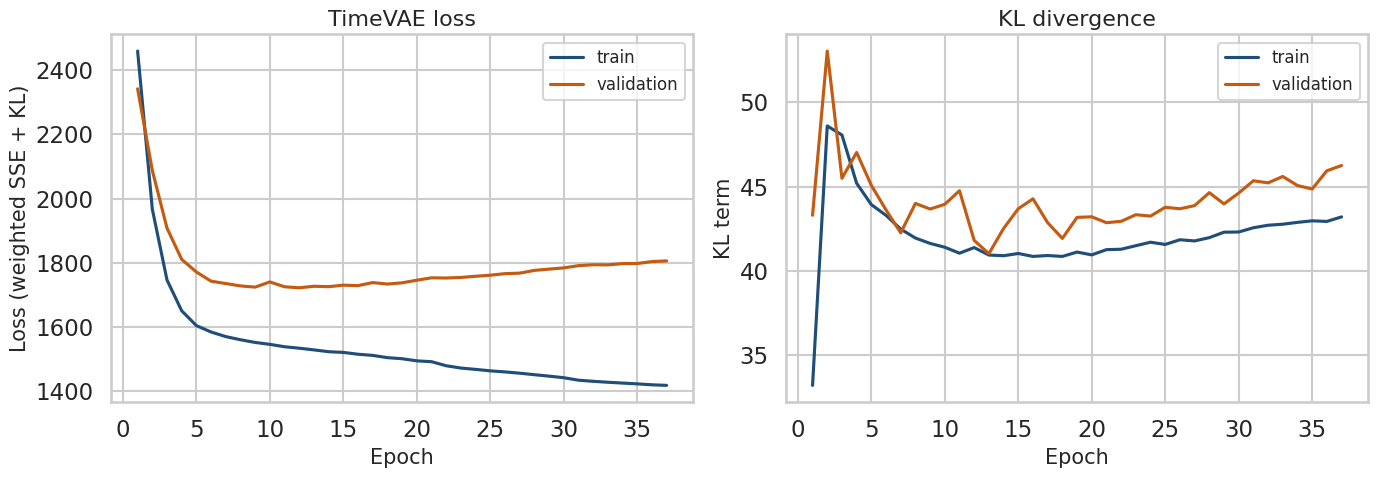

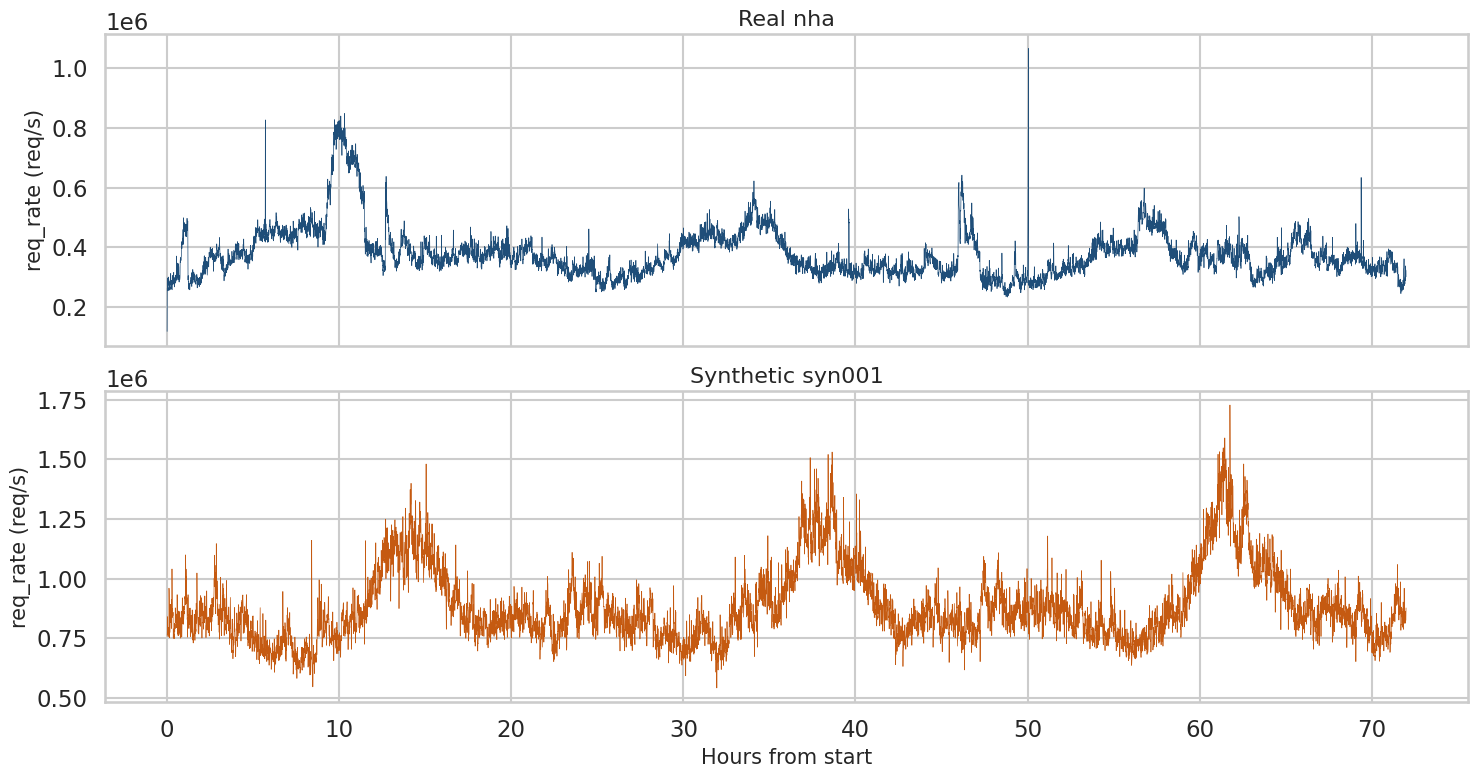

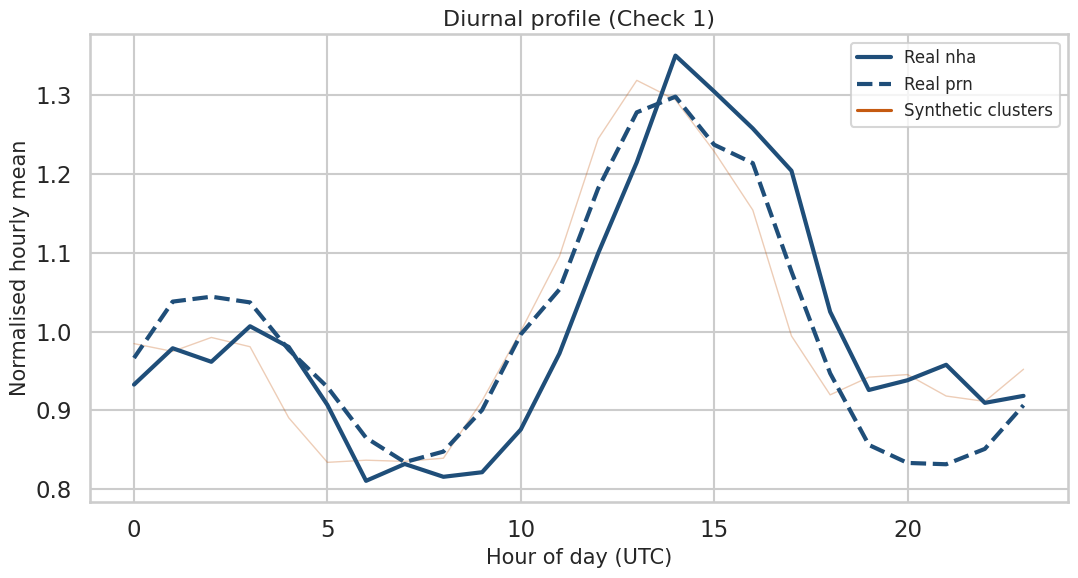

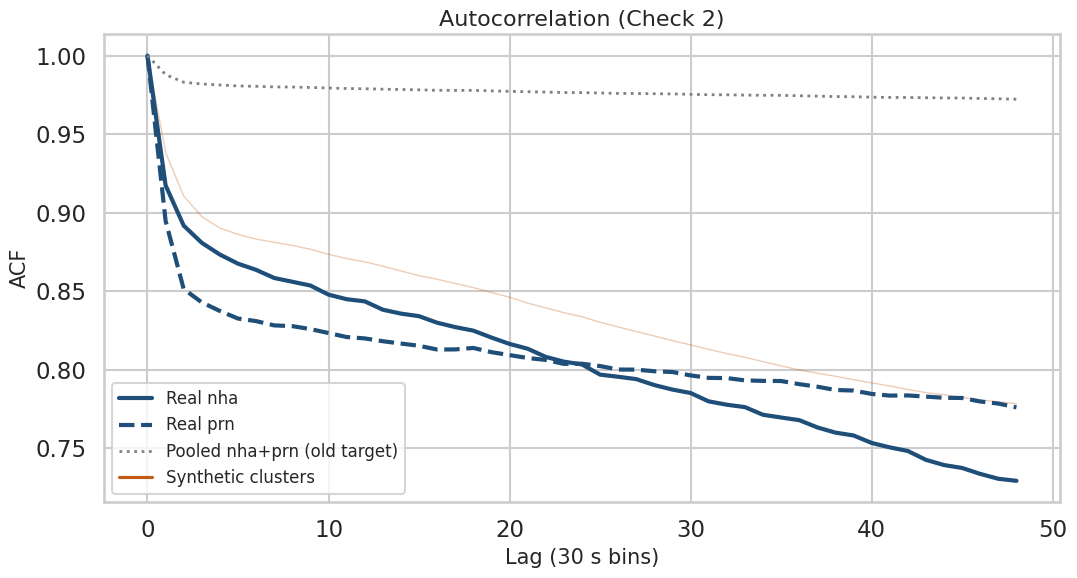

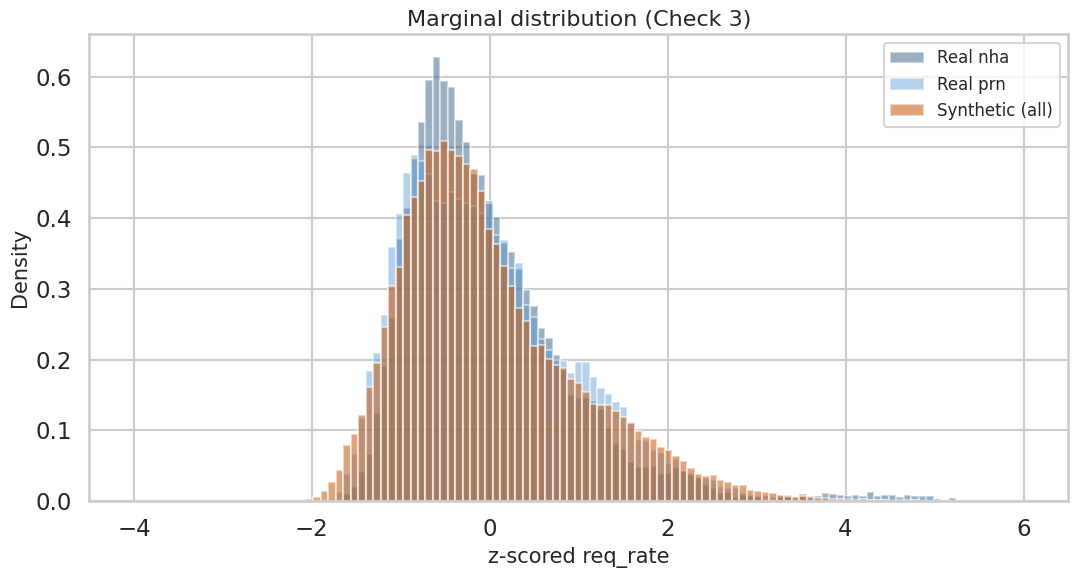

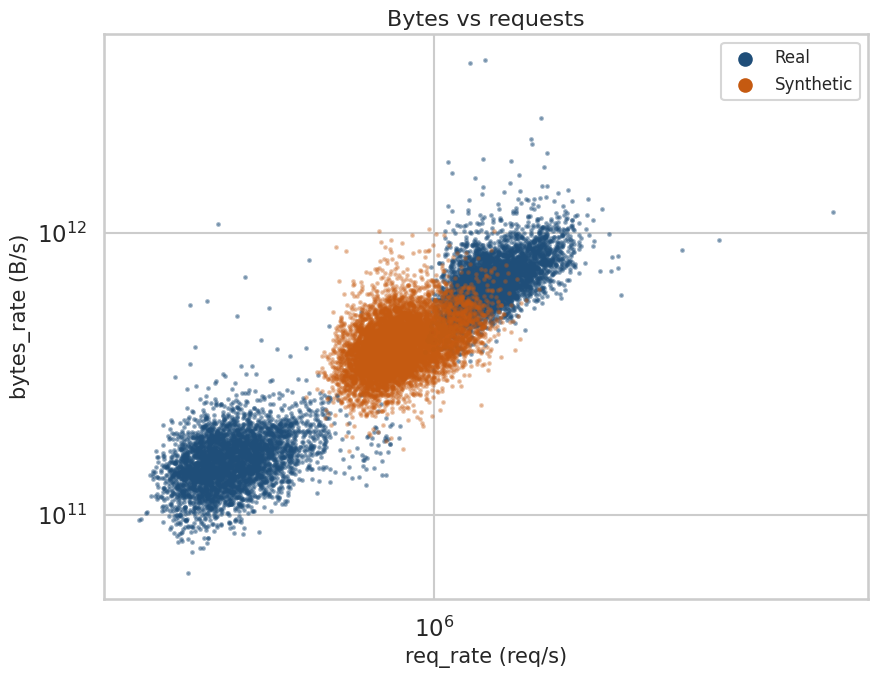

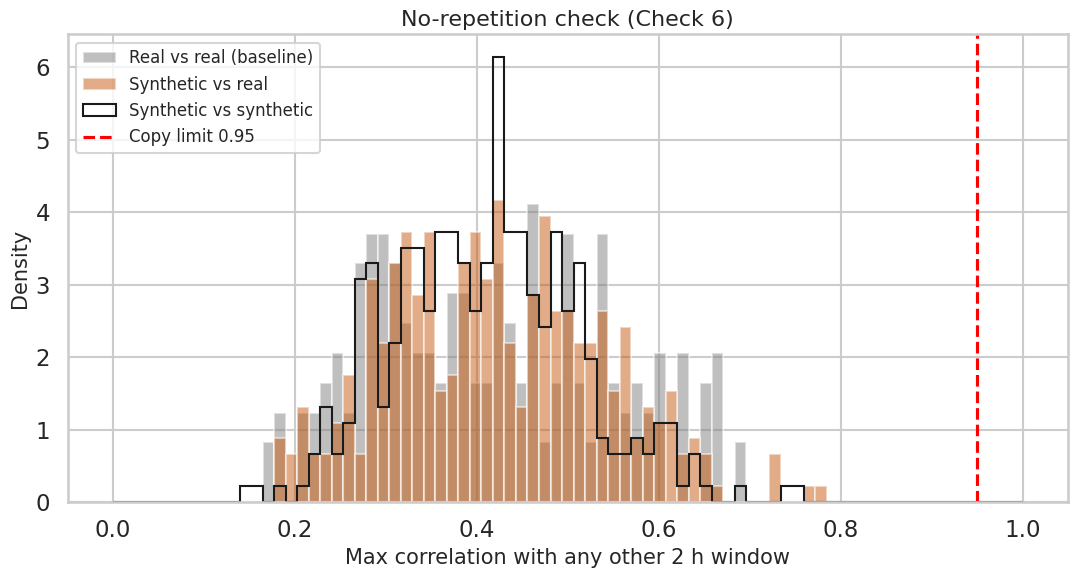

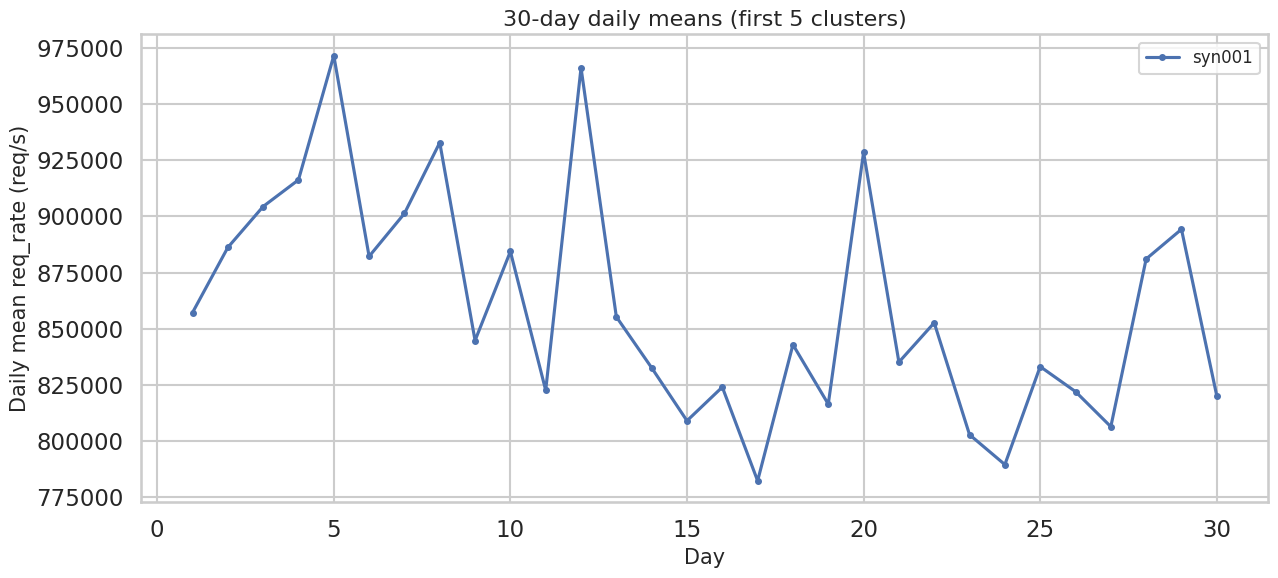

Figures saved in /kaggle/working/timevae_out_baseline/figures


In [21]:
require('syn_dfs', 'hist', 'novelty', 'ref', 'hourly_profile', '_acf')

sns.set_theme(style='whitegrid', context='talk')
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 300, 'font.size': 14,
                     'axes.titlesize': 16, 'axes.labelsize': 15, 'legend.fontsize': 12})
C_REAL, C_SYN = '#1f4e79', '#c55a11'

def save(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name), bbox_inches='tight')
    plt.show()

# Fig 1 - training curves
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(hist['epoch'], hist['train_loss'], label='train', color=C_REAL)
ax[0].plot(hist['epoch'], hist['val_loss'], label='validation', color=C_SYN)
ax[0].set(xlabel='Epoch', ylabel='Loss (weighted SSE + KL)', title='TimeVAE loss'); ax[0].legend()
ax[1].plot(hist['epoch'], hist['train_kl'], color=C_REAL, label='train')
ax[1].plot(hist['epoch'], hist['val_kl'], color=C_SYN, label='validation')
ax[1].set(xlabel='Epoch', ylabel='KL term', title='KL divergence'); ax[1].legend()
save(fig, 'fig1_training_curves.png')

# Fig 2 - three days, real vs synthetic
n3 = 3 * BPD
fig, ax = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for a_, (lab, y, col) in zip(ax, [(f'Real {TRAIN_CLUSTERS[0]}', real[TRAIN_CLUSTERS[0]]['req'][:n3], C_REAL),
                                  ('Synthetic syn001', syn_dfs[0]['req_rate'].values[:n3], C_SYN)]):
    a_.plot(np.arange(len(y)) * GRAN / 3600, y, lw=0.5, color=col); a_.set_title(lab)
    a_.set_ylabel('req_rate (req/s)')
ax[1].set_xlabel('Hours from start')
save(fig, 'fig2_three_days_real_vs_syn.png')

# Fig 3 - hourly diurnal profile
fig, ax = plt.subplots(figsize=(11, 6))
for s in syn_dfs:
    b_ = ((s['ts_bin'].values % 86400) // GRAN).astype(int)
    ax.plot(range(24), hourly_profile(s['req_rate'].values.astype(float), b_, BPD), color=C_SYN, alpha=0.3, lw=1)
for c, ls in zip(TRAIN_CLUSTERS, ['-', '--']):
    ax.plot(range(24), ref['R'][c]['dh'], color=C_REAL, lw=3, ls=ls, label=f'Real {c}')
ax.plot([], [], color=C_SYN, label='Synthetic clusters')
ax.set(xlabel='Hour of day (UTC)', ylabel='Normalised hourly mean', title='Diurnal profile (Check 1)'); ax.legend()
save(fig, 'fig3_diurnal_profile.png')

# Fig 4 - ACF
fig, ax = plt.subplots(figsize=(11, 6))
for s in syn_dfs:
    ax.plot(_acf(s['req_rate'].values.astype(float), 48), color=C_SYN, alpha=0.3, lw=1)
for c, ls in zip(TRAIN_CLUSTERS, ['-', '--']):
    ax.plot(ref['R'][c]['acf'], color=C_REAL, lw=3, ls=ls, label=f'Real {c}')
ax.plot(ref['real_acf_pooled'], color='grey', lw=2, ls=':', label='Pooled nha+prn (old target)')
ax.plot([], [], color=C_SYN, label='Synthetic clusters')
ax.set(xlabel='Lag (30 s bins)', ylabel='ACF', title='Autocorrelation (Check 2)'); ax.legend()
save(fig, 'fig4_acf.png')

# Fig 5 - marginal distribution of z-scores
syn_z = np.concatenate([(s['req_rate'].values - s['req_rate'].values.mean()) / s['req_rate'].values.std()
                        for s in syn_dfs])
fig, ax = plt.subplots(figsize=(11, 6))
bins = np.linspace(-4, 6, 120)
for c, col in zip(TRAIN_CLUSTERS, [C_REAL, '#5b9bd5']):
    ax.hist(ref['R'][c]['z'], bins=bins, density=True, alpha=0.45, color=col, label=f'Real {c}')
ax.hist(syn_z, bins=bins, density=True, alpha=0.55, color=C_SYN, label='Synthetic (all)')
ax.set(xlabel='z-scored req_rate', ylabel='Density', title='Marginal distribution (Check 3)'); ax.legend()
save(fig, 'fig5_marginal_distribution.png')

# Fig 6 - bytes vs requests
rng_p = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(9, 7))
for c in TRAIN_CLUSTERS:
    i = rng_p.choice(len(real[c]['req']), 4000, replace=False)
    ax.scatter(real[c]['req'][i], real[c]['byt'][i], s=4, alpha=0.4, color=C_REAL)
sy = pd.concat(syn_dfs).sample(8000, random_state=0)
ax.scatter(sy['req_rate'], sy['bytes_rate'], s=4, alpha=0.3, color=C_SYN)
ax.scatter([], [], color=C_REAL, label='Real'); ax.scatter([], [], color=C_SYN, label='Synthetic')
ax.set(xscale='log', yscale='log', xlabel='req_rate (req/s)', ylabel='bytes_rate (B/s)',
       title='Bytes vs requests'); ax.legend()
save(fig, 'fig6_bytes_vs_requests.png')

# Fig 7 - novelty
fig, ax = plt.subplots(figsize=(11, 6))
bins = np.linspace(0, 1, 80)
ax.hist(novelty['base'], bins=bins, density=True, alpha=0.5, color='grey', label='Real vs real (baseline)')
ax.hist(novelty['syn_real'], bins=bins, density=True, alpha=0.5, color=C_SYN, label='Synthetic vs real')
ax.hist(novelty['syn_syn'], bins=bins, density=True, histtype='step', lw=2, color='k', label='Synthetic vs synthetic')
ax.axvline(COPY_CORR_HARD, ls='--', color='red', label=f'Copy limit {COPY_CORR_HARD}')
ax.set(xlabel='Max correlation with any other 2 h window', ylabel='Density',
       title='No-repetition check (Check 6)'); ax.legend()
save(fig, 'fig7_no_repetition.png')

# Fig 8 - 30-day daily means
fig, ax = plt.subplots(figsize=(13, 6))
for s in syn_dfs[:5]:
    ax.plot(np.arange(N_DAYS) + 1, s['req_rate'].values.reshape(N_DAYS, BPD).mean(axis=1), marker='o',
            ms=4, label=s['cluster_id'].iloc[0])
ax.set(xlabel='Day', ylabel='Daily mean req_rate (req/s)', title='30-day daily means (first 5 clusters)')
ax.legend(ncol=5)
save(fig, 'fig8_daily_means_30d.png')
print(f'Figures saved in {FIG_DIR}')

## 13. Save the trace and run information

In [22]:
require('syn_dfs', 'metrics', 'summary', 'hist', 'syn_meta', 'FIDELITY')
out = syn_dfs[0][['cluster_id', 'ts_bin', 'req_rate', 'bytes_rate']]
assert len(out) == N_DAYS * BPD == 86_400 and out['ts_bin'].diff().dropna().eq(GRAN).all()
out.to_csv(OUTPUT_CSV, index=False)
run_info = dict(experiment=EXPERIMENT, seed=SEED, gran=GRAN, n_days=N_DAYS,
                train_clusters=TRAIN_CLUSTERS, test_cluster=TEST_CLUSTER, window=WINDOW,
                overlap=OVERLAP, latent_dim=LATENT_DIM, hidden=HIDDEN, recon_wt=RECON_WT,
                epochs_run=int(hist['epoch'].max()), best_val_loss=float(best), active_latent_dims=active,
                noise=[dict(ar_coefs=n['coefs'].tolist(), sigma_e=n['sigma_e'], dist=n['dist'],
                            hour_mult=np.round(n['hour_mult'], 3).tolist()) for n in NOISE],
                day_sigma=DAY_SIGMA, day_phi=DAY_PHI, checks=summary, fidelity=FIDELITY,
                tstr_15=TSTR15, real_cleaning=cleaning_log, trace=syn_meta[0])
if 'CAL' in globals():
    run_info['calendar'] = {k: {kk: (vv.tolist() if hasattr(vv, 'tolist') else vv) for kk, vv in v.items()}
                            for k, v in CAL.items()}
if 'HAWKES' in globals():
    run_info['bursts'] = dict(hawkes=HAWKES, gpd=list(GPD), peak_cap_log=PEAK_CAP_LOG, geom_p=GEOM_P, decay=DECAY)
with open(os.path.join(OUT_DIR, 'run_info.json'), 'w') as f:
    json.dump(run_info, f, indent=2, default=str)
print(f'Saved one 30-day trace: {len(out):,} rows -> {OUTPUT_CSV}')
print(f'Six checks passed: {sum(v for v in summary.values() if v is not None)}/6   FIDELITY: {FIDELITY:.3f}')

Saved one 30-day trace: 86,400 rows -> /kaggle/working/timevae_out_baseline/synthetic_cdn_baseline.csv
Six checks passed: 5/6   FIDELITY: 0.545


In [23]:
import shutil
from pathlib import Path

out_dir = Path("/kaggle/working/timevae_out_baseline")

if not out_dir.exists():
    raise FileNotFoundError(
        "Output folder missing. Run the experiment first."
    )

zip_path = shutil.make_archive(
    "/kaggle/working/timevae_baseline_results",
    "zip",
    root_dir=str(out_dir)
)

print("Results archived at:", zip_path)

Results archived at: /kaggle/working/timevae_baseline_results.zip
